In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [23]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [3]:
import h5py
from astropy.io import ascii

In [4]:
from lmfit import Model

In [5]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [6]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [7]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs.h5','r')

In [8]:
data

<HDF5 file "coadds_outputs.h5" (mode r)>

In [9]:
data.keys()

<KeysViewHDF5 ['EXPRES', 'NEID', 'overlaps']>

In [10]:
data['NEID']

<HDF5 group "/NEID" (4 members)>

In [11]:
data['NEID'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [12]:
for key in data['NEID']['coadds'].keys():
    #if the shape is greater than 1, print the key and shape
    if data['NEID']['coadds'][key].shape[0]>1:
        print(key, data['NEID']['coadds'][key].shape)

0076 (122, 9216)
0077 (122, 9216)


In [13]:
list(data['NEID']['coadds']['0076'])

[array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([-0.02807862, -0.04519362,  0.06150555, ...,  0.07337227,
         0.03466464,  0.11789358]),
 array([-0.20199334, -0.11950385,  0.10707734, ...,  0.00486623,
         0.07061568, -0.01625383]),
 array([-0.06784297,  0.18237221, -0.08384315, ...,  0.24565483,
         0.2134005 ,  0.28661534]),
 array([ 0.10441111,  0.05873122, -0.17328135, ...,  0.2281816 ,
         0.21236393,  0.24535008]),
 array([-0.17816692, -0.09170772, -0.21126223, ...,  0.35397781,
         0.34404274,  0.36887214]),
 array([-0.15908799, -0.03416314,  0.00894035, ...,  0.53096045,
         0.49649486,  0.50691684]),
 array([0.15710612, 0.12739878, 0.23076561, ..., 0.33414429, 0.31962956,
      

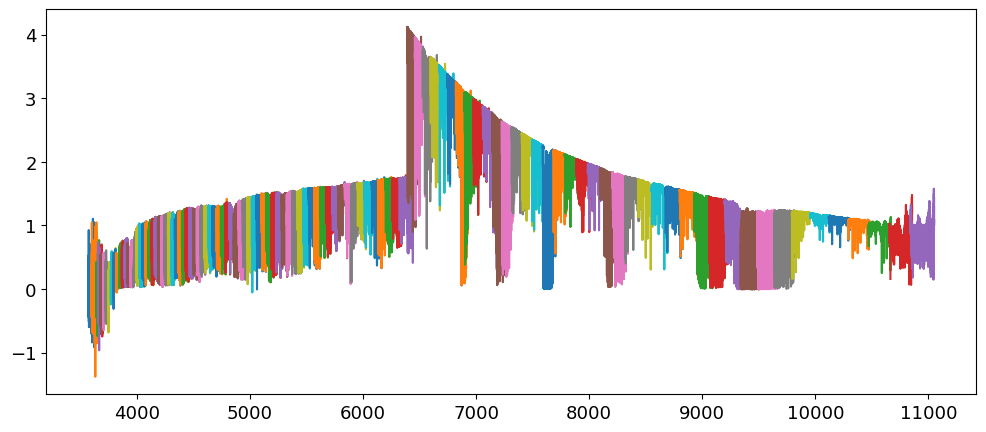

In [14]:
for o in range(data['NEID']['coadds']['0076'].shape[0]):
    #if the mean wavelength is greater than 1000, plot the coadd
    if np.mean(data['NEID']['wls']['0076'][o])>1000:
        plt.plot(data['NEID']['wls']['0076'][o],data['NEID']['coadds']['0076'][o])

In [15]:
np.array(data['NEID']['coadds']['0076'])

array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [1.19532844, 1.69411556, 1.43916054, ..., 0.39184273, 0.20450761,
        0.58336822],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]])

In [32]:
np.array(data['NEID']['coadds'])

array(['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007',
       '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015',
       '0016', '0017', '0018', '0019', '0020', '0021', '0022', '0023',
       '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031',
       '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039',
       '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047',
       '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055',
       '0056', '0057', '0058', '0059', '0060', '0061', '0062', '0063',
       '0064', '0065', '0066', '0067', '0068', '0069', '0070', '0071',
       '0072', '0073', '0074', '0075', '0076', '0077', '0078', '0079',
       '0080', '0081', '0082', '0083', '0084', '0085', '0086', '0087',
       '0088', '0089', '0090', '0091', '0092', '0093', '0094', '0095',
       '0096', '0097', '0098', '0099', '0100', '0101', '0102', '0103',
       '0104', '0105', '0106', '0107', '0108', '0109', '0110', '0111',
      

In [33]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]

for key in  data['NEID']['coadds'].keys():
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)

NEID coadds found for key: 0076
EXPRES coadds found for key: 0076
NEID coadds found for key: 0077
EXPRES coadds found for key: 0077


In [16]:
#read in csv file with line list
line_list_loc="../../RvLineList_allowBlends=0_overlapCutoff=5.0e-6_blend_RV_cutoff=2.0_depthCutoff=0.02_rejectTelluricSlope=2000.0_badLineFilter=none_quant=95_nbin=1_DP=true_binParam=depth_n=1_long_output=true_VACUUM.csv"

In [17]:
line_list=ascii.read(line_list_loc)

In [18]:
line_list

median_a,median_b,depth,median_σ²,lambda,std_a,std_b,std_depth,std_σ²,std_λc,line_id,frac_converged,bool_filter_min_frac_converged,bool_filter_median_depth_between_5percent_and_1,bool_filter_std_velocity_width_quant,bool_filter_std_local_continuum_slope_quant,bool_filter_neg_bad_line,bool_filter_nan_bad_line,bool_filter_rejectTelluricSlope,mean_template_var,species,excitation_energy,oscillator_strength,random,VALD_index,bool_filter_depth_cutoff,blend_number,bool_filter_allowBlends,bool_filter_blend_factors,bool_filter_iron1Only,bool_filter_badLineFilter,passed_all_bool_filters,weight
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,str4,str4,str4,str4,str4,str4,str4,float64,str6,float64,float64,float64,int64,str4,int64,str4,str4,str4,str4,str4,float64
1.390579184732739,-0.736072586417786,0.5150686662735857,0.0030234554953981075,3882.134036576609,0.02439298588736176,0.20423282963296344,0.01965792911191175,6.5379850964047366e-18,0.00011574880226041941,1,0.98,true,true,true,true,true,true,true,3.710046719196202e-05,'CN 1',0.4408,0.158,0.9798758118202728,33033,true,0,true,true,true,true,true,0.5150686662735857
1.4626195513611164,2.0,0.4626482900339974,0.0030243662221938394,3882.7272483847664,0.019833374917207196,0.007672694908955968,0.01443748436186155,1.7434626923745965e-18,0.0006491785020339457,3,0.99,true,true,true,true,true,true,true,3.564773193456217e-05,'CN 1',0.4014,0.138,0.15113742968704924,33074,true,0,true,true,true,true,true,0.4626482900339974
1.080508576002649,0.1397195269004936,0.29994065149636995,0.0009497331051758072,3884.7318502049066,0.02972422717267476,0.23898141525578726,0.01780264614315196,0.0001333542369734463,0.0009502448774235051,9,1.0,true,true,true,true,true,true,true,3.246203613563732e-05,'Cr 1',3.01,-0.599,0.39172948354773496,33307,true,0,true,true,true,true,true,0.29994065149636995
1.863776296921765,0.2643072533328039,0.8143328137705086,0.002030448740766423,3886.6115251666934,0.09596850898710192,0.1473562660555812,0.006841660425169698,0.00013218379606930224,0.00022699752539482516,14,1.0,true,true,true,true,true,true,true,2.6533833861963513e-05,'Fe 1',2.4242,-1.085,0.5255726323555064,33381,true,0,true,true,true,true,true,0.8143328137705086
1.262949730475054,-0.5452096008076086,0.4102918511992903,0.00090078658500036,3886.84777055226,0.06904214339493916,0.37289140709410873,0.02974329167646794,0.00015760911899441528,0.0009163318854588962,15,1.0,true,true,true,true,true,true,true,2.471094958998301e-05,'Fe 1',3.2657,-1.293,0.5215974726374468,33390,true,0,true,true,true,true,true,0.4102918511992903
1.3293268255814517,-0.7740967357370896,0.5368364403682011,0.000984484901598761,3887.8962318114072,0.043662121339747,0.2520133494325407,0.014896529232831301,8.953489630896986e-05,0.00048278510033959894,16,1.0,true,true,true,true,true,true,true,1.966537156689862e-05,'Cr 1',1.0037,-1.37,0.01912161666492629,33426,true,0,true,true,true,true,true,0.5368364403682011
2.1635697865732184,0.2685066022753484,0.8508276156364669,0.004458197631188673,3888.152342013541,0.12692224023212992,0.18163515915575534,0.0071796954527459204,0.00032741801907894925,0.00037184395643818474,17,1.0,true,true,true,true,true,true,true,2.024679331386678e-05,'Fe 1',0.9146,-1.144,0.8626210645618242,33436,true,0,true,true,true,true,true,0.8508276156364669
1.4981018441580132,1.79549506707687,0.7848770984491065,0.003035105759696383,3889.6170975366504,0.04022393090592791,0.20932390837985476,0.0019021460522598715,1.3075970192809475e-18,0.0008777396497513403,18,1.0,true,true,true,true,true,true,true,1.6549513719364787e-05,'Fe 1',1.6079,-0.548,0.885453401184154,33480,true,0,true,true,true,true,true,0.7848770984491065
1.396534590550099,-0.7935461514660569,0.7175433190929252,0.0012598659674836529,3891.940572510654,0.05335205353984595,0.1456570187272362,0.005989275701351141,5.1134490635896625e-05,0.0001917519518226411,26,1.0,true,true,true,true,true,true,true,1.8560433676389046e-05,'Fe 1',2.7275,-1.313,0.30295011059313

In [19]:
line_list['lambda']

3882.134036576609
3882.7272483847664
3884.7318502049066
3886.6115251666934
3886.84777055226
3887.8962318114072
3888.152342013541
3889.6170975366504
3891.940572510654
3893.0273958264756
3893.405436375459


In [20]:
gmod=Model(gaussian_w_slope)

In [21]:
w=np.array(data['NEID']['wls']['0076'])
s=np.array(data['NEID']['coadds']['0076'])

In [70]:


def fit_lines(w,s,line_list,plot=False,wl_min=6000,wl_max=6030,fit_range=1,dist_from_edge=500):
    line_fits=[]
    '''fits lines in line_list to the spectrum s with wavelengths w
    
        inputs are:
            w: 2D array of wavelengths (orders x pixels)
            s: 2D array of spectrum (orders x pixels)
            line_list: astropy table with columns 'lambda' and 'depth'
    '''
    for i,l in enumerate(line_list['lambda'].value):
        if l<wl_max and l>wl_min:
            #print(l,line_list['depth'][i])
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            orders_with_line=[] 

            for o in range(w.shape[0]):
                if l>w[o].min()+dist_from_edge*(w[o][1]-w[o][0]) and l<w[o].max()-dist_from_edge*(w[o][1]-w[o][0]):
                    orders_with_line.append(o)
            #print("orders with line:",orders_with_line)
            #for each order, convert the wavelength to velocity, centered on the line wavelength and then fit a guassian to the spectrum
            #only fit within 2 angstroms of the line center
            for o in orders_with_line: 
                wl_order=w[o]
                s_order=s[o]
                vel_order=wl2vel(wl_order,central_wl=l)
                #select only the points within 1 angstroms of the line center
                mask=(wl_order>l-fit_range)&(wl_order<l+fit_range)
                wl_fit=wl_order[mask]
                s_fit=s_order[mask]
                vel_fit=vel_order[mask]
                #initial guess for the gaussian parameters
                amp_init=line_list['depth'][i]*np.sum(s_fit)*-1
                cen_init=0
                wid_init=3.0
                bas_init=np.median(s_fit)
                slope_init=0
                params=gmod.make_params(amp=amp_init,cen=cen_init,wid=wid_init,bas=bas_init,slope=slope_init)
                #fit the gaussian to the data
                result=gmod.fit(s_fit,params,x=vel_fit)
                #print(result.fit_report())
                if plot:
                    #plot the data and the fit
                    plt.figure()
                    plt.plot(vel_fit,s_fit,label='data')
                    plt.plot(vel_fit,result.best_fit,label='fit')
                    plt.xlabel('Velocity (km/s)')
                    plt.ylabel('Flux')
                    plt.title(f'Order {o} Line at {l} Angstroms')
                    plt.legend()
                    plt.show()
                
                
                #save the fit results to a list
                line_fits.append({'line_wl':l,'order':o,'amp':result.params['amp'].value,'amp_err':result.params['amp'].stderr,    
                                  'cen':result.params['cen'].value,
                                  'cen_err':result.params['cen'].stderr,
                                  'wid':result.params['wid'].value,
                                  'wid_err':result.params['wid'].stderr,
                                  'bas':result.params['bas'].value,
                                  'bas_err':result.params['bas'].stderr,
                                  'slope':result.params['slope'].value,'chi2':result.chisqr,
                                  'bic':result.bic,'r':result.rsquared})
    
    return line_fits
            

In [71]:
result

In [72]:
result.R

AttributeError: 'ModelResult' object has no attribute 'R'

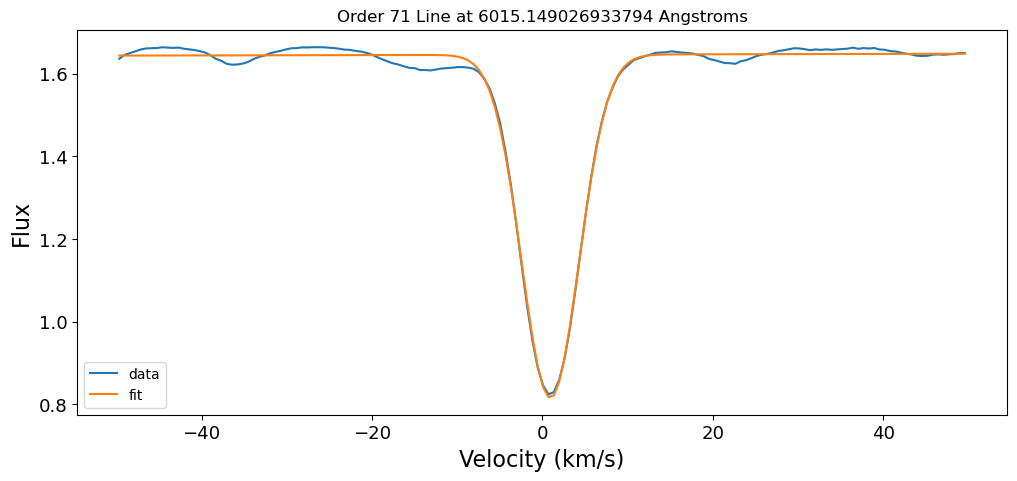

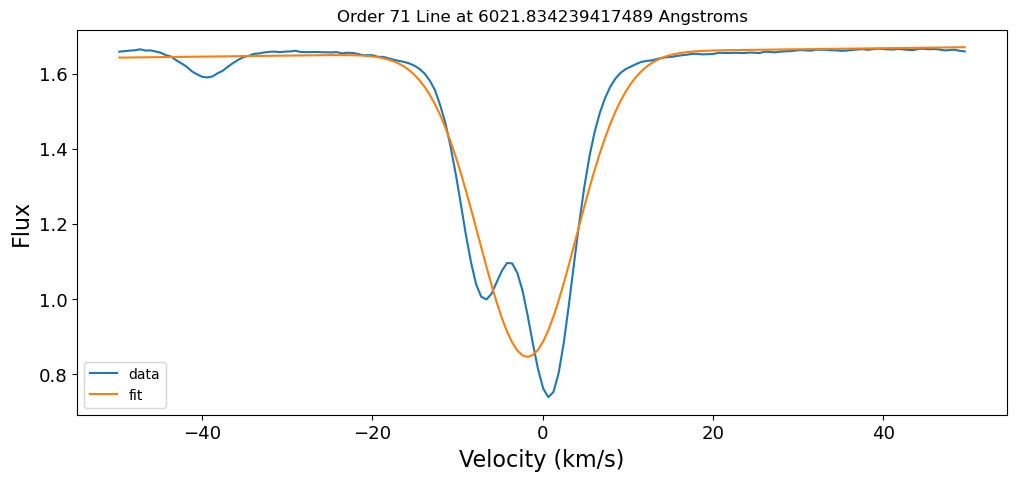

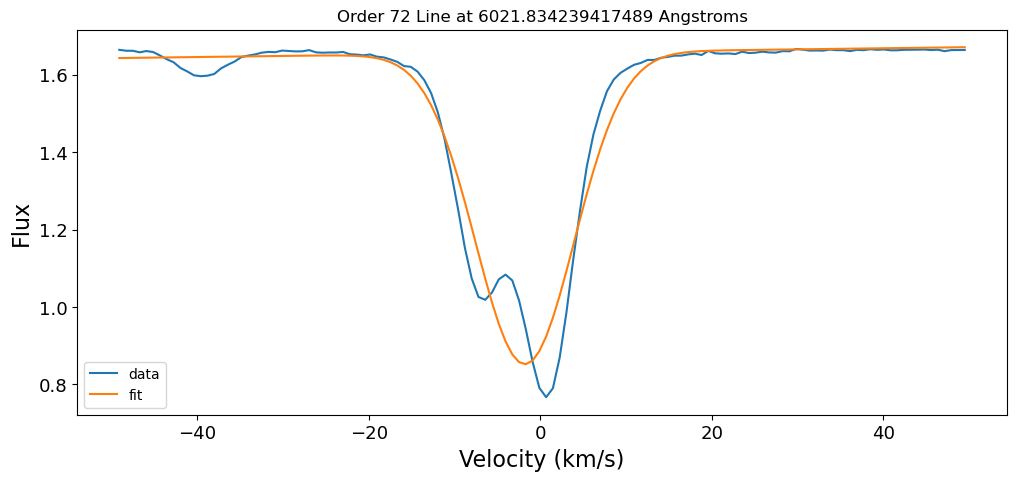

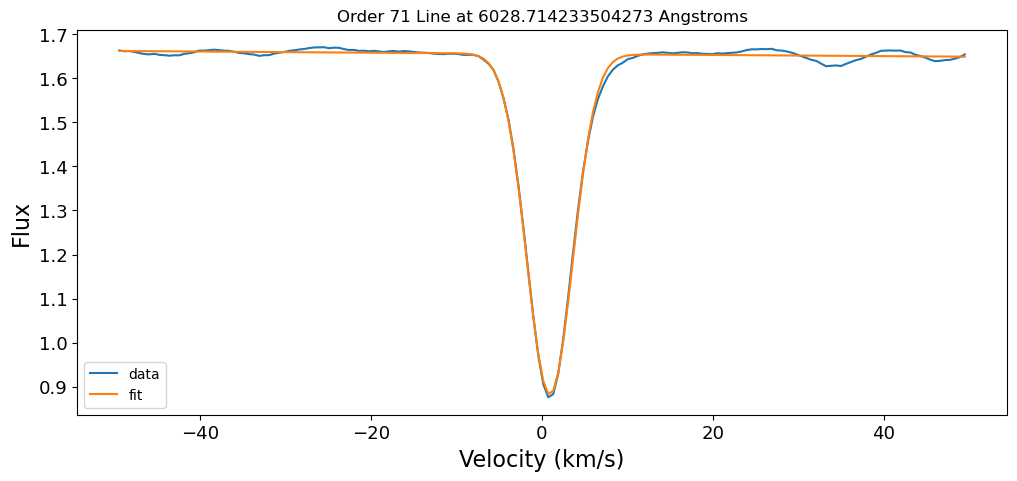

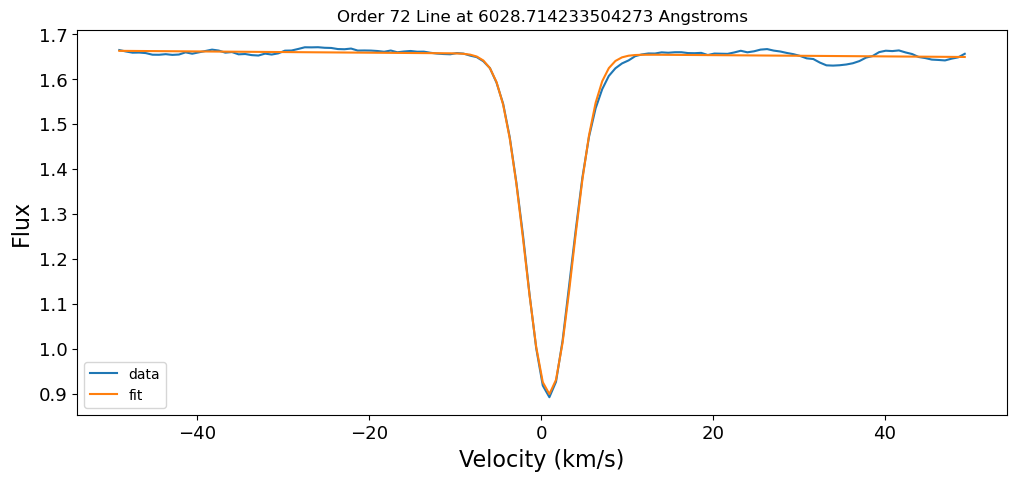

In [73]:
fit_res=fit_lines(w,s,line_list,plot=True,wl_min=6000,wl_max=6030,fit_range=1,dist_from_edge=500)

In [74]:
fit_res

[{'line_wl': 6015.149026933794,
  'order': 71,
  'amp': -6.986960281376121,
  'amp_err': 0.05245078135479753,
  'cen': 0.9212299115906791,
  'cen_err': 0.026398456374562278,
  'wid': 3.3553855727241473,
  'wid_err': 0.02729632101482949,
  'bas': 1.646086051276254,
  'bas_err': 0.001242678290137353,
  'slope': 4.535765458469311e-05,
  'chi2': 0.031053666562303146,
  'bic': -1332.6653514431673,
  'r': 0.9946351647541941},
 {'line_wl': 6021.834239417489,
  'order': 71,
  'amp': -11.655671092969152,
  'amp_err': 0.30122734477603774,
  'cen': -1.7801947193470131,
  'cen_err': 0.143660010016497,
  'wid': 5.733293854838782,
  'wid_err': 0.15262748503211654,
  'bas': 1.6569640490345092,
  'bas_err': 0.005454735663248581,
  'slope': 0.0002784341502566929,
  'chi2': 0.5455255645753494,
  'bic': -916.9422015276107,
  'r': 0.9417723709654915},
 {'line_wl': 6021.834239417489,
  'order': 72,
  'amp': -11.598976109214885,
  'amp_err': 0.3165671530888134,
  'cen': -1.7894586534770955,
  'cen_err': 0.1

In [75]:
fit_lines(w,s/1.6,line_list,wl_min=6000,wl_max=6030,fit_range=1,dist_from_edge=500)

[{'line_wl': 6015.149026933794,
  'order': 71,
  'amp': -4.366850175856638,
  'amp_err': 0.03278173834736297,
  'cen': 0.9212299115670509,
  'cen_err': 0.02639845637310332,
  'wid': 3.3553855727228474,
  'wid_err': 0.02729632101465222,
  'bas': 1.0288037820476323,
  'bas_err': 0.0007766739313374879,
  'slope': 2.8348533839410543e-05,
  'chi2': 0.012130338500899668,
  'bic': -1482.126505543311,
  'r': 0.9946351647541941},
 {'line_wl': 6021.834239417489,
  'order': 71,
  'amp': -7.284794433091959,
  'amp_err': 0.18826709047981438,
  'cen': -1.780194719323578,
  'cen_err': 0.14366001001904008,
  'wid': 5.73329385482641,
  'wid_err': 0.1526274850280698,
  'bas': 1.035602530646423,
  'bas_err': 0.0034092097894616144,
  'slope': 0.00017402134397457038,
  'chi2': 0.21309592366224583,
  'bic': -1072.0433991787033,
  'r': 0.9417723709654915},
 {'line_wl': 6021.834239417489,
  'order': 72,
  'amp': -7.249360068284421,
  'amp_err': 0.19785447068295334,
  'cen': -1.7894586534756918,
  'cen_err': 0

In [76]:
#time how long this cell takes to run
%time fit_lines(w,s/1.6,line_list,wl_min=4000,wl_max=8030,fit_range=1,dist_from_edge=500)

ValueError: The model function generated NaN values and the fit aborted! Please check your model function and/or set boundaries on parameters where applicable. In cases like this, using "nan_policy='omit'" will probably not work.